<a href="https://colab.research.google.com/github/Jorgellamocca/S2S-PER/blob/main/Lima_diario.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive


Inicialización UTC: 2026-11-02 00:00:00
Resolución: 0.1 grados
Horizonte: 120 horas


<multiple>:   0%|          | 0.00/10.1M [00:00<?, ?B/s]

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.
GRIB descargado: /content/ifs_tp.grib2
NetCDF: /content/drive/MyDrive/ECMWF_IFS/LIMA_PP_5DIAS/IFS_PP_DIARIA_LIMA_20261102_00Z.nc


/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


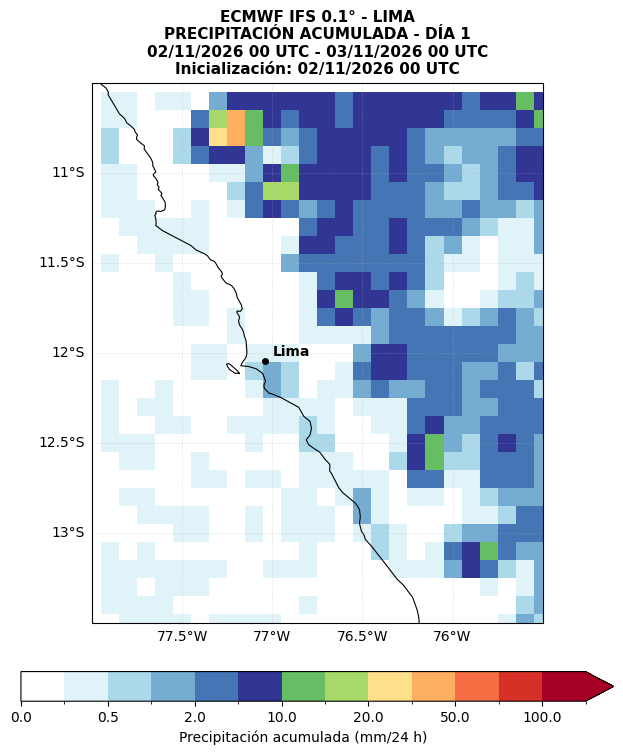

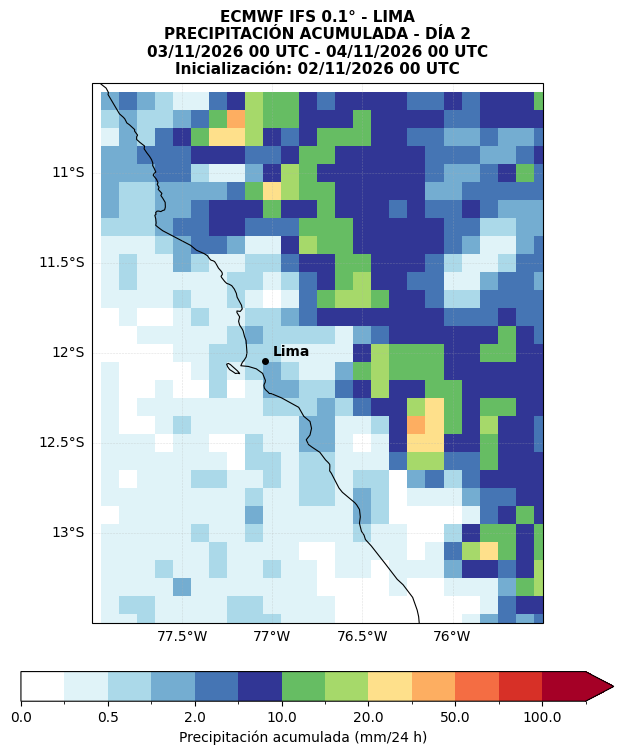

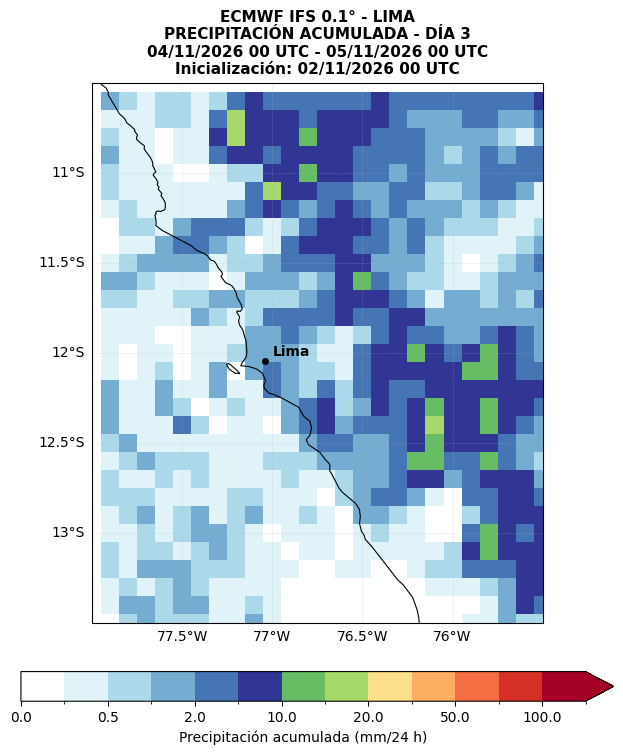

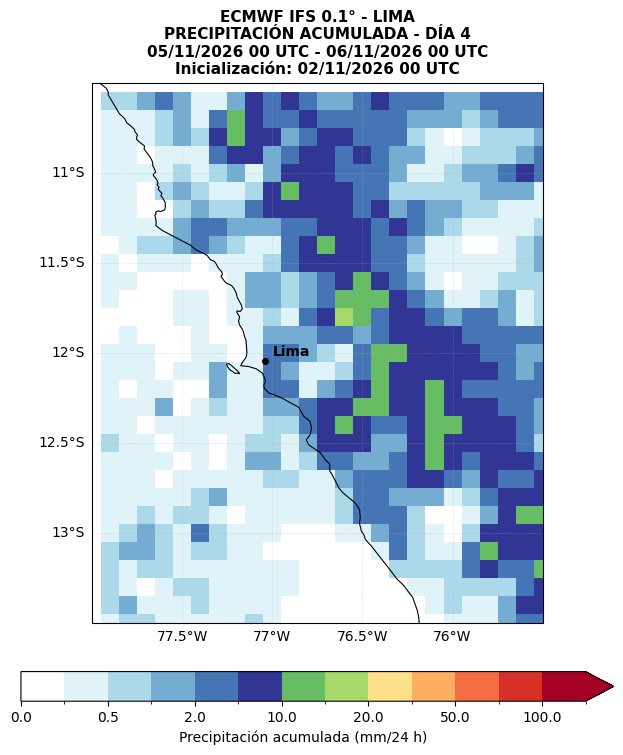

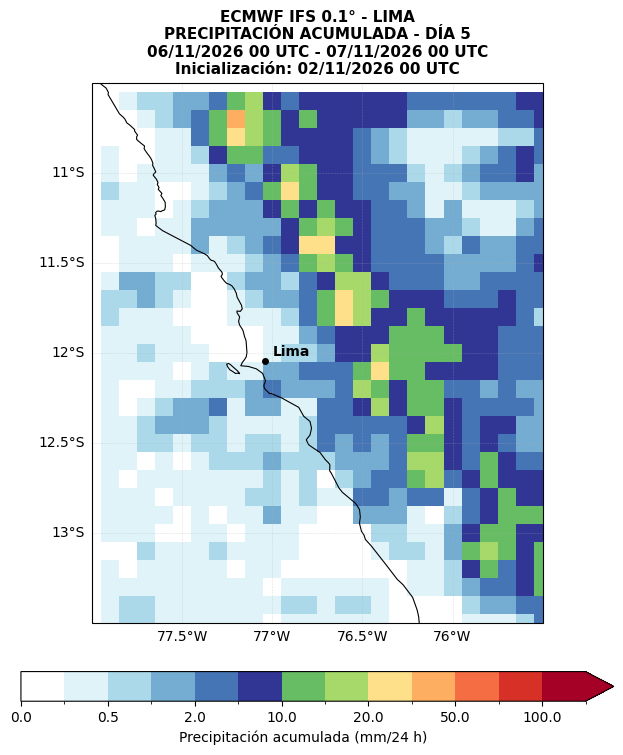


RESUMEN PRECIPITACIÓN
 Dia Inicio_UTC    Fin_UTC  PP_media_mm  PP_max_mm
   1 2026-11-02 2026-11-03     1.791016  30.761719
   2 2026-11-03 2026-11-04     3.831543  33.447266
   3 2026-11-04 2026-11-05     2.338542  16.845703
   4 2026-11-05 2026-11-06     2.412760  18.554688
   5 2026-11-06 2026-11-07     3.375977  30.517578

ARCHIVOS GUARDADOS EN:
/content/drive/MyDrive/ECMWF_IFS/LIMA_PP_5DIAS


In [1]:
# ============================================================
# ECMWF IFS 0.1° - PRECIPITACIÓN DIARIA EN LIMA
# Pronóstico: 5 días (0-120 horas)
# Salidas: 5 PNG + NetCDF + CSV
# Plataforma: Google Colab
# ============================================================

!pip -q install -U ecmwf-opendata cfgrib eccodes xarray \
    netCDF4 cartopy geopandas

import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from pathlib import Path
from datetime import timedelta
from google.colab import drive
from ecmwf.opendata import Client

# ------------------------------------------------------------
# 1. GOOGLE DRIVE
# ------------------------------------------------------------

drive.mount("/content/drive")

ROOT = Path(
    "/content/drive/MyDrive/ECMWF_IFS/LIMA_PP_5DIAS"
)
ROOT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. CONFIGURACIÓN
# ------------------------------------------------------------

# Lima Metropolitana y entorno regional
LON_MIN, LON_MAX = -78.0, -75.5
LAT_MIN, LAT_MAX = -13.5, -10.5

PASOS = [0, 24, 48, 72, 96, 120]

client = Client(
    source="ecmwf",
    model="ifs",
    resol="0p1"
)

# ------------------------------------------------------------
# 3. ÚLTIMO CICLO COMPLETO DISPONIBLE
# ------------------------------------------------------------

ciclos = []

for hora in [0, 12]:
    try:
        fecha = client.latest(
            time=hora,
            stream="oper",
            type="fc",
            levtype="sfc",
            step=120,
            param="tp"
        )
        if fecha is not None:
            ciclos.append(fecha)
    except Exception as e:
        print(f"Ciclo {hora:02d}: {e}")

if not ciclos:
    raise RuntimeError(
        "No hay ciclos completos disponibles."
    )

inicio = max(ciclos)

FECHA = inicio.strftime("%Y%m%d")
HORA = inicio.hour

print("Inicialización UTC:", inicio)
print("Resolución: 0.1 grados")
print("Horizonte: 120 horas")

# ------------------------------------------------------------
# 4. DESCARGA DE PRECIPITACIÓN TOTAL
# ------------------------------------------------------------

archivo_grib = Path("/content/ifs_tp.grib2")

client.retrieve(
    date=FECHA,
    time=HORA,
    stream="oper",
    type="fc",
    levtype="sfc",
    step=PASOS,
    param="tp",
    target=str(archivo_grib)
)

print("GRIB descargado:", archivo_grib)

# ------------------------------------------------------------
# 5. ABRIR DATOS
# ------------------------------------------------------------

ds = xr.open_dataset(
    archivo_grib,
    engine="cfgrib",
    backend_kwargs={"indexpath": ""}
)

tp = ds["tp"]

# Convertir longitudes 0-360 a -180/180
tp = tp.assign_coords(
    longitude=(
        (tp.longitude + 180) % 360
    ) - 180
)

tp = tp.sortby("longitude")

# Recortar región de Lima
tp = tp.sel(
    longitude=slice(LON_MIN, LON_MAX)
)

if tp.latitude.values[0] > tp.latitude.values[-1]:
    tp = tp.sel(
        latitude=slice(LAT_MAX, LAT_MIN)
    )
else:
    tp = tp.sel(
        latitude=slice(LAT_MIN, LAT_MAX)
    )

# ------------------------------------------------------------
# 6. CALCULAR ACUMULADOS DIARIOS
# ------------------------------------------------------------

precipitacion_diaria = []

for i in range(1, len(PASOS)):

    anterior = tp.isel(step=i-1).values
    actual = tp.isel(step=i).values

    # Convertir m a mm
    diaria = (actual - anterior) * 1000.0

    # Evitar negativos por errores numéricos
    diaria = np.maximum(diaria, 0)

    precipitacion_diaria.append(diaria)

pp = xr.DataArray(
    np.stack(precipitacion_diaria),
    dims=["dia", "latitude", "longitude"],
    coords={
        "dia": np.arange(1, 6),
        "latitude": tp.latitude.values,
        "longitude": tp.longitude.values
    },
    name="precipitacion_diaria"
)

pp.attrs["units"] = "mm"
pp.attrs["description"] = (
    "Precipitación acumulada en intervalos de 24 horas"
)

pp.attrs["source"] = "ECMWF IFS 0.1"

# ------------------------------------------------------------
# 7. GUARDAR NETCDF
# ------------------------------------------------------------

archivo_nc = ROOT / (
    f"IFS_PP_DIARIA_LIMA_{FECHA}_{HORA:02d}Z.nc"
)

pp.to_netcdf(archivo_nc)

print("NetCDF:", archivo_nc)

# ------------------------------------------------------------
# 8. CONFIGURACIÓN DE MAPAS
# ------------------------------------------------------------

niveles = [
    0, 0.1, 0.5, 1, 2, 5,
    10, 15, 20, 30, 50,
    75, 100, 150
]

colores = [
    "#FFFFFF",
    "#E0F3F8",
    "#ABD9E9",
    "#74ADD1",
    "#4575B4",
    "#313695",
    "#66BD63",
    "#A6D96A",
    "#FEE08B",
    "#FDAE61",
    "#F46D43",
    "#D73027",
    "#A50026"
]

cmap = mcolors.ListedColormap(colores)
norm = mcolors.BoundaryNorm(
    niveles,
    cmap.N,
    clip=True
)

resumen = []

# ------------------------------------------------------------
# 9. GENERAR LOS 5 MAPAS
# ------------------------------------------------------------

for i in range(5):

    campo = pp.isel(dia=i)

    fecha_inicio = inicio + timedelta(
        hours=PASOS[i]
    )

    fecha_fin = inicio + timedelta(
        hours=PASOS[i+1]
    )

    fig = plt.figure(figsize=(9, 9))

    ax = plt.axes(
        projection=ccrs.PlateCarree()
    )

    ax.set_extent(
        [LON_MIN, LON_MAX, LAT_MIN, LAT_MAX],
        crs=ccrs.PlateCarree()
    )

    im = ax.pcolormesh(
        campo.longitude,
        campo.latitude,
        campo.values,
        cmap=cmap,
        norm=norm,
        shading="auto",
        transform=ccrs.PlateCarree()
    )

    ax.coastlines(
        resolution="10m",
        linewidth=0.8
    )

    ax.add_feature(
        cfeature.BORDERS,
        linewidth=0.5
    )

    # Ubicación de Lima
    ax.plot(
        -77.0428,
        -12.0464,
        marker="o",
        color="black",
        markersize=4,
        transform=ccrs.PlateCarree()
    )

    ax.text(
        -77.0,
        -12.02,
        "Lima",
        fontsize=10,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.4,
        alpha=0.4,
        linestyle="--"
    )

    gl.top_labels = False
    gl.right_labels = False

    cbar = plt.colorbar(
        im,
        ax=ax,
        orientation="horizontal",
        pad=0.07,
        shrink=0.85,
        extend="max"
    )

    cbar.set_label(
        "Precipitación acumulada (mm/24 h)"
    )

    ax.set_title(
        f"ECMWF IFS 0.1° - LIMA\n"
        f"PRECIPITACIÓN ACUMULADA - DÍA {i+1}\n"
        f"{fecha_inicio:%d/%m/%Y %H UTC} - "
        f"{fecha_fin:%d/%m/%Y %H UTC}\n"
        f"Inicialización: {inicio:%d/%m/%Y %H UTC}",
        fontsize=11,
        fontweight="bold"
    )

    nombre = (
        f"IFS_PP_LIMA_DIA_{i+1}_"
        f"{FECHA}_{HORA:02d}Z.png"
    )

    plt.savefig(
        ROOT / nombre,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    valores = campo.values

    resumen.append({
        "Dia": i+1,
        "Inicio_UTC": fecha_inicio,
        "Fin_UTC": fecha_fin,
        "PP_media_mm": float(np.nanmean(valores)),
        "PP_max_mm": float(np.nanmax(valores))
    })

# ------------------------------------------------------------
# 10. TABLA RESUMEN
# ------------------------------------------------------------

tabla = pd.DataFrame(resumen)

archivo_csv = ROOT / (
    f"IFS_PP_RESUMEN_LIMA_{FECHA}_{HORA:02d}Z.csv"
)

tabla.to_csv(archivo_csv, index=False)

print("\nRESUMEN PRECIPITACIÓN")
print(tabla.to_string(index=False))

print("\nARCHIVOS GUARDADOS EN:")
print(ROOT)